<a href="https://colab.research.google.com/github/umutkilictas/chronic-kidney-disease-ml/blob/main/VeriAnalizi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pandas scikit-learn matplotlib


In [ ]:
import pandas as pd
import numpy as np

# CSV dosyasini oku (hem yerel hem Colab uyumlu)
file_path = "kidney_disease.csv"
df = pd.read_csv(file_path)

print("Boyut (Satir, Sutun):", df.shape)
print("Sutunlar:", list(df.columns))
df.head()


FileNotFoundError: [Errno 2] No such file or directory: '/content/kidney_disease.csv'

KNN Accuracy: 0.9750 (97.50%)
Logistic Regression Accuracy: 1.0000 (100.00%)
Decision Tree Accuracy: 1.0000 (100.00%)
Naive Bayes Accuracy: 0.9875 (98.75%)


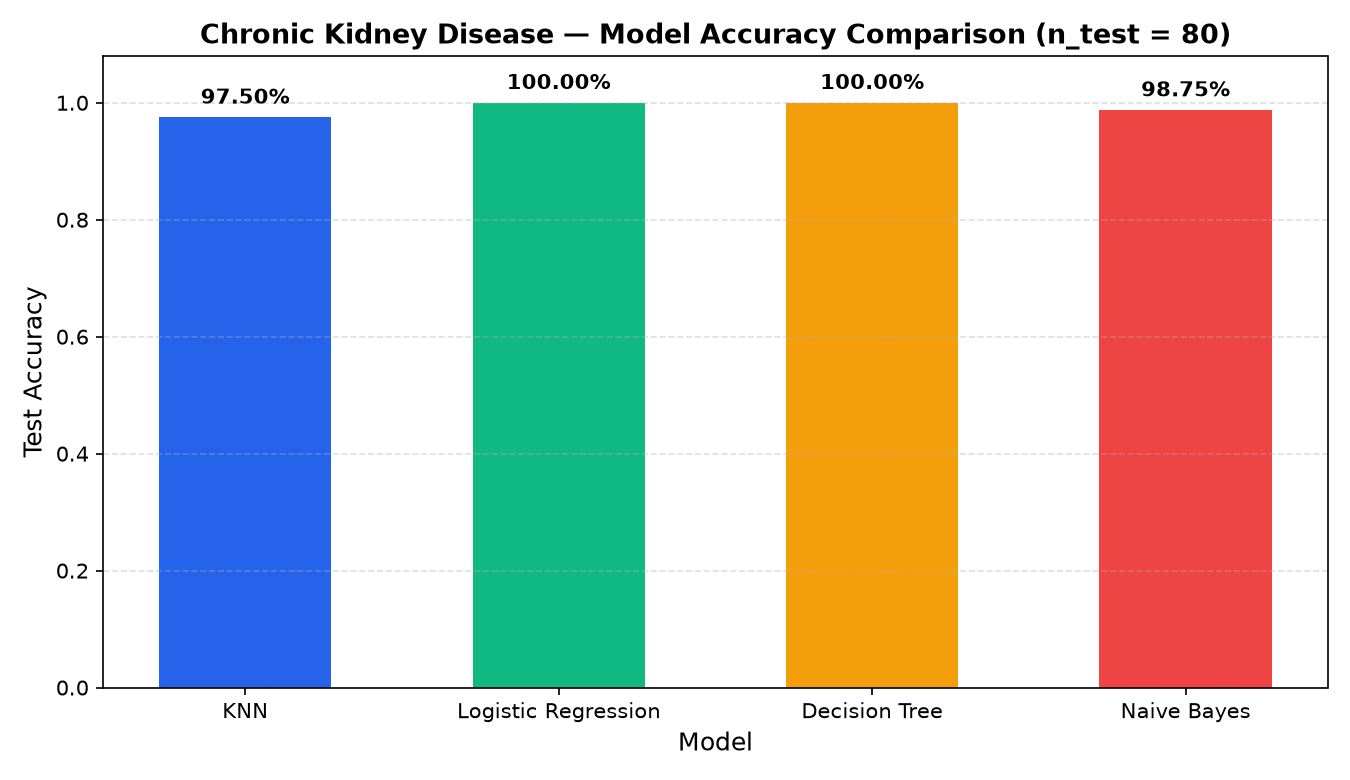

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

# 1. Veri Sizintisini (Data Leakage) onlemek icin sira numarasi (id) sutununu cikar
if "id" in df.columns:
    df = df.drop(columns=["id"])

# 2. Metin sutunlarindaki gizli sekme (\t), bosluk ve "?" karakterlerini temizle
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace({"?": np.nan, "nan": np.nan, "": np.nan})

# 3. Sayisal ve kategorik sutunlari tanimla
numeric_columns = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]
categorical_columns = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane", "classification"]

# 4. Sayisal sutunlari float tipine cevir ve eksik degerleri medyan ile doldur
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].median())

# 5. Kategorik sutunlardaki eksik degerleri mod ile doldur ve LabelEncoder uygula
label_encoders = {}
for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
        label_encoders[col] = le

# 6. Bagimsiz (X) ve hedef (y: ckd=0, notckd=1) degiskenleri ayir
X = df.drop("classification", axis=1)
y = df["classification"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. Ozellik olcekleme (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 8. Modelleri egit ve degerlendir
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
}

accuracies = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    accuracies.append(acc)
    print(f"{name} Accuracy: {acc:.4f} ({acc*100:.2f}%)")

# 9. Dogruluk karsilastirma grafigi
plt.figure(figsize=(9, 5.2))
bars = plt.bar(list(models.keys()), accuracies, color=["#2563eb", "#10b981", "#f59e0b", "#ef4444"], width=0.55)
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.title("Chronic Kidney Disease — Model Accuracy Comparison (n_test = 80)")
plt.ylim(0, 1.08)
plt.grid(axis="y", linestyle="--", alpha=0.4)
for bar, v in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v*100:.2f}%", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()
